# 01 – Data Exploration & Preprocessing (Milestone 1)
**Project:** AI-Based Credit Card Fraud Detection | **Course:** INSE 6450

Runs end to end in Google Colab: *Runtime → Run all*.

## 1. Import libraries

In [1]:
import os
import sys
import shutil
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Folders for saved outputs (relative paths)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

## 2. Download the train / test data from Kaggle
Dataset: [kartik2112/fraud-detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection)

Uses `kagglehub`, which normally downloads public datasets without any setup. If Kaggle asks for it, a login box appears (Kaggle username + API token from Kaggle → Settings → API).

In [2]:
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub

def download_data():
    """Download the dataset and copy the train/test CSVs into the current folder."""
    path = Path(kagglehub.dataset_download("kartik2112/fraud-detection"))
    for name in ("fraudTrain.csv", "fraudTest.csv"):
        shutil.copy(next(path.rglob(name)), name)

if not (os.path.exists("fraudTrain.csv") and os.path.exists("fraudTest.csv")):
    try:
        download_data()
    except Exception as e:
        print("Anonymous download failed:", e)
        print("Please log in to Kaggle below, then the download will retry.")
        kagglehub.login()
        download_data()

print("CSV files:", [f for f in os.listdir(".") if f.endswith(".csv")])

Using Colab cache for faster access to the 'fraud-detection' dataset.
CSV files: ['fraudTrain.csv', 'fraudTest.csv']


## 3. Load the data and check what it contains

In [3]:
train_df = pd.read_csv("fraudTrain.csv")
test_df = pd.read_csv("fraudTest.csv")

# Drop the unnamed index column (not a real feature)
train_df = train_df.drop(columns=["Unnamed: 0"], errors="ignore")
test_df = test_df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Number of original features:", train_df.shape[1] - 1)

Train shape: (1296675, 22)
Test shape: (555719, 22)
Number of original features: 21


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  object 
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  object 
 3   category               1296675 non-null  object 
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  object 
 6   last                   1296675 non-null  object 
 7   gender                 1296675 non-null  object 
 8   street                 1296675 non-null  object 
 9   city                   1296675 non-null  object 
 10  state                  1296675 non-null  object 
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop          

In [5]:
train_df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


## 4. Data quality: missing values and duplicates

In [6]:
missing_values = train_df.isnull().sum()
missing_values = missing_values[missing_values > 0]
print("Missing values per column:")
print(missing_values if len(missing_values) else "None")

print("\nDuplicate rows (train):", train_df.duplicated().sum())
print("Duplicate transaction ids (train):", train_df["trans_num"].duplicated().sum())

Missing values per column:
None

Duplicate rows (train): 0
Duplicate transaction ids (train): 0


In [7]:
train_df[["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]].describe()

,amt,city_pop,lat,long,merch_lat,merch_long
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,7.035104e+01,8.882444e+04,3.853762e+01,-9.022634e+01,3.853734e+01,-9.022646e+01
std,1.603160e+02,3.019564e+05,5.075808e+00,1.375908e+01,5.109788e+00,1.377109e+01
min,1.000000e+00,2.300000e+01,2.002710e+01,-1.656723e+02,1.902779e+01,-1.666712e+02
25%,9.650000e+00,7.430000e+02,3.462050e+01,-9.679800e+01,3.473357e+01,-9.689728e+01
50%,4.752000e+01,2.456000e+03,3.935430e+01,-8.747690e+01,3.936568e+01,-8.743839e+01
75%,8.314000e+01,2.032800e+04,4.194040e+01,-8.015800e+01,4.195716e+01,-8.023680e+01
max,2.894890e+04,2.906700e+06,6.669330e+01,-6.795030e+01,6.751027e+01,-6.695090e+01


## 5. Class distribution
Fraud is extremely rare, so accuracy is misleading; later milestones will use precision, recall, F1 and PR-AUC.

In [8]:
train_counts = train_df["is_fraud"].value_counts().sort_index()
test_counts = test_df["is_fraud"].value_counts().sort_index()

summary = pd.DataFrame({
    "train_count": train_counts, "train_%": (train_counts / train_counts.sum() * 100).round(3),
    "test_count": test_counts,   "test_%": (test_counts / test_counts.sum() * 100).round(3),
})
summary.index = ["Legitimate (0)", "Fraud (1)"]
print(summary)
print(f"\nImbalance ratio (train): {train_counts[0] / train_counts[1]:.0f} : 1")

                train_count  train_%  test_count  test_%
Legitimate (0)      1289169   99.421      553574  99.614
Fraud (1)              7506    0.579        2145   0.386

Imbalance ratio (train): 172 : 1


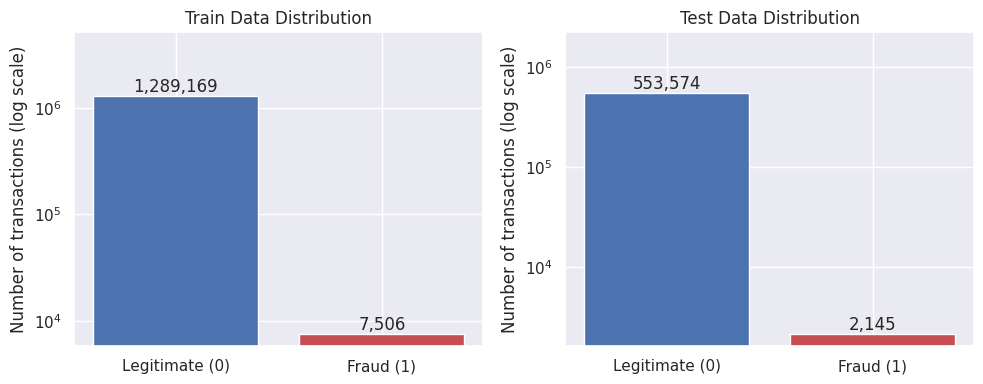

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, counts, title in zip(axes, (train_counts, test_counts), ("Train", "Test")):
    bars = ax.bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=["#4c72b0", "#c44e52"])
    ax.set_yscale("log")                   # fraud is too rare to see on a linear scale
    ax.set_ylim(top=counts.max() * 4)
    ax.set_title(f"{title} Data Distribution")
    ax.set_ylabel("Number of transactions (log scale)")
    for b, v in zip(bars, counts.values):
        ax.annotate(f"{v:,}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom")
plt.tight_layout()

plt.savefig("outputs/figures/class_distribution.pdf", bbox_inches="tight")
plt.savefig("outputs/figures/class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Fraud patterns

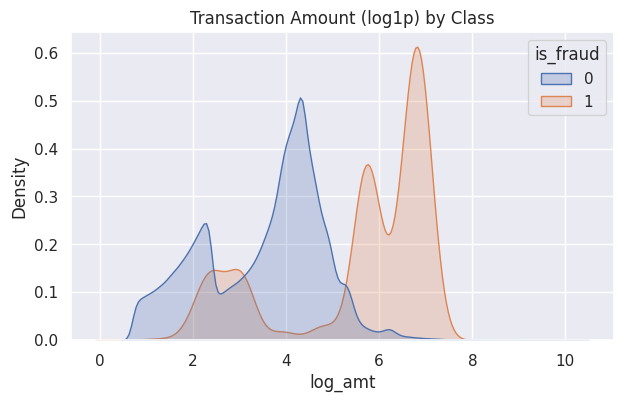

In [10]:
# Transaction amount by class (log scale because amounts are right-skewed)
plt.figure(figsize=(7, 4))
sns.kdeplot(data=train_df.assign(log_amt=np.log1p(train_df["amt"])),
            x="log_amt", hue="is_fraud", common_norm=False, fill=True)
plt.title("Transaction Amount (log1p) by Class")
plt.savefig("outputs/figures/amount_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Outlier check (IQR rule)

In [11]:
numeric_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]
outlier_summary = {}

for col in numeric_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = train_df[(train_df[col] < Q1 - 1.5 * IQR) | (train_df[col] > Q3 + 1.5 * IQR)]
    outlier_summary[col] = len(outliers)

print("Outlier count (IQR rule):")
print(outlier_summary)

Outlier count (IQR rule):
{'amt': 67290, 'city_pop': 242674, 'lat': 4679, 'long': 49922, 'merch_lat': 4967, 'merch_long': 41994}
